# Walmart Sales Forecasting and Demand Prediction
### Complete end-to-end Google Colab notebook

**Purpose:** analyse Walmart's historical weekly sales and forecast demand to support inventory planning, reduce overstocking and avoid stockouts.

This notebook is deliberately organized as a guided project report. Each stage explains **what we are doing, why we are doing it, the code, and how to interpret the output**.

### Models implemented
1. Seasonal Naive baseline
2. Random Forest Regressor
3. XGBoost Regressor
4. LSTM (Long Short-Term Memory)
5. SARIMA (seasonal time-series model)

### Forecasting level and fair comparison
The original project concerns demand across stores and departments. To make SARIMA practical while preserving department-level demand, this notebook aggregates weekly sales **by department across Walmart stores**. Each model predicts the same Department–Week target, and all models are evaluated on the same held-out weeks. The result supports department-level demand planning; it does not claim to provide separate store-level forecasts.

### Validation design
- Sort the unique weekly dates chronologically.
- Use the first 80% of dates for training and the final 20% for validation.
- For the supplied dataset this should be 114 training weeks and 29 validation weeks.
- Use a rolling one-week-ahead validation: actual sales from earlier validation weeks may be used as history to predict the next week.
- This is **not** a 29-week forecast made all at once.

**Important:** the historical dataset ends on 26 October 2012. This notebook measures historical forecasting performance; it does not represent live Walmart sales in 2026.

## 1. Business problem and project objectives

Walmart has many stores and departments. Ordering too much inventory ties up money and can create storage costs and unsold stock. Ordering too little can cause stockouts, lost sales and customer dissatisfaction.

**Project objective:** use historical weekly sales, calendar information, holiday indicators and economic features to forecast future demand. Compare different forecasting approaches and identify the strongest model using validation metrics.

### Questions this notebook answers
- What does the historical sales data look like?
- Are sales different during holiday weeks?
- Which features may help explain weekly demand?
- How do five forecasting models perform on unseen historical weeks?
- Which model has the lowest validation error?
- How can the forecast support inventory decisions?

### Expected outputs
- Exploratory data analysis charts.
- Clean department-week modelling dataset.
- Five trained forecasting approaches.
- MAE, RMSE and WMAE comparison table.
- Actual-versus-predicted plots and residual analysis.
- Saved models, metrics, validation forecasts and metadata.

## 2. Dataset description

Use the **Walmart Recruiting Store Sales Forecasting** dataset.

| File | Purpose |
|---|---|
| `train.csv` | Historical Store, Department, Date, IsHoliday and Weekly_Sales |
| `features.csv` | Weekly external features such as temperature, fuel price, CPI, unemployment and markdowns |
| `stores.csv` | Store metadata such as Type and Size |
| `test.csv` | Competition records with withheld Weekly_Sales; not used to calculate validation accuracy |
| `sampleSubmission.csv` | Example competition submission format |

### Known dataset facts
The original training file contains 421,570 rows, 45 stores, 81 departments and 143 unique weekly dates from 5 February 2010 to 26 October 2012.

The target variable is **`Weekly_Sales`**.

## 3. Install the required libraries

Google Colab already includes many data-science packages. This cell installs or updates the packages needed for XGBoost and the statistical models.

**Run this cell first and wait for it to finish.**

In [1]:
!pip -q install --upgrade xgboost statsmodels scikit-learn joblib

## 4. Upload the original Walmart dataset

Upload the original dataset ZIP file that contains `train.csv`, `features.csv`, and `stores.csv`. You may instead upload those CSV files individually.

Do **not** upload this notebook as the dataset. The notebook and dataset are separate files.

In [2]:
from google.colab import files
uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))

Saving features.csv.zip to features.csv.zip
Saving sampleSubmission.csv.zip to sampleSubmission.csv.zip
Saving stores.csv to stores.csv
Saving test.csv.zip to test.csv.zip
Saving train.csv.zip to train.csv.zip
Uploaded files: ['features.csv.zip', 'sampleSubmission.csv.zip', 'stores.csv', 'test.csv.zip', 'train.csv.zip']


## 5. Extract the ZIP and locate the CSV files

The next cell searches inside the uploaded ZIP and any nested folders. It automatically identifies the folder containing `train.csv`, `features.csv`, and `stores.csv`.

If a required file is missing, the cell stops and explains which file needs to be uploaded.

In [3]:
from pathlib import Path
import zipfile

ROOT = Path("/content/walmart_dataset")
ROOT.mkdir(parents=True, exist_ok=True)

for filename in uploaded:
    source = Path("/content") / filename
    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(source, "r") as archive:
            archive.extractall(ROOT)
    elif filename.lower().endswith(".csv"):
        (ROOT / filename).write_bytes(source.read_bytes())

train_candidates = list(ROOT.rglob("train.csv"))
if not train_candidates:
    raise FileNotFoundError(
        "train.csv was not found. Upload the original Walmart ZIP or the required CSV files."
    )

DATA_DIR = train_candidates[0].parent
required = ["train.csv", "features.csv", "stores.csv"]
missing = [name for name in required if not (DATA_DIR / name).exists()]
if missing:
    raise FileNotFoundError(f"Missing required CSV files in {DATA_DIR}: {missing}")

print("Dataset directory:", DATA_DIR)
print("Available files:", sorted(p.name for p in DATA_DIR.iterdir() if p.is_file()))

Dataset directory: /content/walmart_dataset
Available files: ['features.csv', 'sampleSubmission.csv', 'stores.csv', 'test.csv', 'train.csv']


## 6. Import libraries and set a random seed

- **Pandas / NumPy:** data manipulation and numerical calculations.
- **Matplotlib:** charts.
- **Scikit-learn:** Random Forest, preprocessing and evaluation metrics.
- **XGBoost:** gradient-boosted trees.
- **PyTorch:** LSTM neural network.
- **Statsmodels:** SARIMA.
- **Joblib:** saving model objects.

A fixed random seed makes randomized parts of the experiment more reproducible.

In [4]:
import os, json, random, warnings, math, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from statsmodels.tsa.statespace.sarimax import SARIMAX

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch device:", DEVICE)

PyTorch device: cpu


## 7. Load the raw CSV files

We load the three core files separately before merging them. This allows us to inspect the raw data and verify that each file has the expected columns.

In [5]:
train_raw = pd.read_csv(DATA_DIR / "train.csv")
features_raw = pd.read_csv(DATA_DIR / "features.csv")
stores_raw = pd.read_csv(DATA_DIR / "stores.csv")

print("train.csv shape:", train_raw.shape)
print("features.csv shape:", features_raw.shape)
print("stores.csv shape:", stores_raw.shape)

display(train_raw.head())
display(features_raw.head())
display(stores_raw.head())

train.csv shape: (421570, 5)
features.csv shape: (8190, 12)
stores.csv shape: (45, 3)


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


## 8. Understand the columns

The training data includes:
- `Store`: store identifier.
- `Dept`: department identifier.
- `Date`: week date.
- `Weekly_Sales`: actual weekly sales (our prediction target).
- `IsHoliday`: whether the week is marked as a holiday.

The feature file contains economic and promotional context. The store file contains store type and size.

This step is important because the target column must not accidentally be included as an input feature for the same row.

In [6]:
print("Training columns:")
print(train_raw.columns.tolist())
print("\nFeature columns:")
print(features_raw.columns.tolist())
print("\nStore columns:")
print(stores_raw.columns.tolist())

print("\nTarget summary:")
display(train_raw["Weekly_Sales"].describe().to_frame())

Training columns:
['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday']

Feature columns:
['Store', 'Date', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'IsHoliday']

Store columns:
['Store', 'Type', 'Size']

Target summary:


,Weekly_Sales
count,421570.000000
mean,15981.258123
std,22711.183519
min,-4988.940000
25%,2079.650000
50%,7612.030000
75%,20205.852500
max,693099.360000


## 9. Check data quality before merging

We check:
- Missing values.
- Duplicate Store–Department–Date records.
- Number of stores, departments and dates.
- Date range.

The original dataset should have no duplicate Store–Department–Date rows. Missing values in external features are expected and will be handled later.

In [7]:
train_check = train_raw.copy()
train_check["Date"] = pd.to_datetime(train_check["Date"])

print("Training rows:", len(train_check))
print("Unique stores:", train_check["Store"].nunique())
print("Unique departments:", train_check["Dept"].nunique())
print("Unique dates:", train_check["Date"].nunique())
print("Date range:", train_check["Date"].min().date(), "to", train_check["Date"].max().date())
print("Duplicate Store-Dept-Date rows:",
      train_check.duplicated(["Store", "Dept", "Date"]).sum())

display(train_check.isna().sum().to_frame("Missing values"))

Training rows: 421570
Unique stores: 45
Unique departments: 81
Unique dates: 143
Date range: 2010-02-05 to 2012-10-26
Duplicate Store-Dept-Date rows: 0


,Missing values
Store,0
Dept,0
Date,0
Weekly_Sales,0
IsHoliday,0


## 10. Merge sales, store and feature information

We merge:
1. Sales with store metadata using `Store`.
2. The result with external features using `Store`, `Date` and `IsHoliday`.

The merge validation checks that the right-hand tables do not unexpectedly duplicate rows. We then create basic calendar columns.

In [8]:
train_raw["Date"] = pd.to_datetime(train_raw["Date"])
features_raw["Date"] = pd.to_datetime(features_raw["Date"])

df = train_raw.merge(
    stores_raw, on="Store", how="left", validate="many_to_one"
)
df = df.merge(
    features_raw,
    on=["Store", "Date", "IsHoliday"],
    how="left",
    validate="many_to_one"
)

df["IsHolidayInt"] = df["IsHoliday"].astype(int)
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Week"] = df["Date"].dt.isocalendar().week.astype(int)
df["Day"] = df["Date"].dt.day

for col in [f"MarkDown{i}" for i in range(1, 6)]:
    if col in df.columns:
        df[col] = df[col].fillna(0)

df = df.sort_values(["Date", "Store", "Dept"]).reset_index(drop=True)

print("Merged dataset shape:", df.shape)
print("Duplicate Store-Dept-Date rows:", df.duplicated(["Store", "Dept", "Date"]).sum())
display(df.head())

Merged dataset shape: (421570, 21)
Duplicate Store-Dept-Date rows: 0


,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,Fuel_Price,MarkDown1,...,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHolidayInt,Year,Month,Week,Day
0,1,1,2010-02-05,24924.50,False,A,151315,42.31,2.572,0.0,...,0.0,0.0,0.0,211.096358,8.106,0,2010,2,5,5
1,1,2,2010-02-05,50605.27,False,A,151315,42.31,2.572,0.0,...,0.0,0.0,0.0,211.096358,8.106,0,2010,2,5,5
2,1,3,2010-02-05,13740.12,False,A,151315,42.31,2.572,0.0,...,0.0,0.0,0.0,211.096358,8.106,0,2010,2,5,5
3,1,4,2010-02-05,39954.04,False,A,151315,42.31,2.572,0.0,...,0.0,0.0,0.0,211.096358,8.106,0,2010,2,5,5
4,1,5,2010-02-05,32229.38,False,A,151315,42.31,2.572,0.0,...,0.0,0.0,0.0,211.096358,8.106,0,2010,2,5,5


## 11. Handle missing external feature values

Markdown fields are filled with zero when no markdown value is recorded. Other numerical features can have missing values.

For modelling, we will fit a median imputer on the **training period only** and apply that same imputer to validation data. This avoids using validation-period information to calculate training preprocessing values.

In [9]:
numeric_external = [
    c for c in ["Temperature", "Fuel_Price", "CPI", "Unemployment", "Size"]
    if c in df.columns
]
print("Missing values in external numeric columns:")
display(df[numeric_external].isna().sum().to_frame("Missing count"))

Missing values in external numeric columns:


,Missing count
Temperature,0
Fuel_Price,0
CPI,0
Unemployment,0
Size,0


## 12. Exploratory Data Analysis: overall weekly sales

We aggregate all store and department sales by week and plot the total. This chart helps us see broad trends, fluctuations and possible seasonal changes.

**Interpretation:** look for recurring peaks, dips and changes over time. Do not assume every peak is caused by a holiday without checking the holiday data.

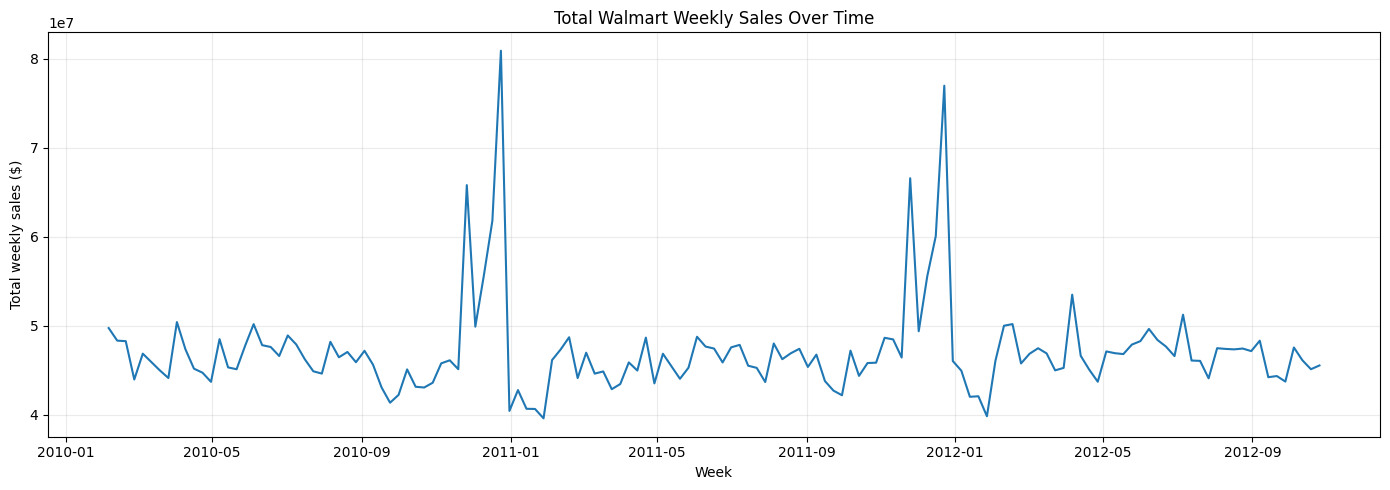

In [10]:
weekly_total_eda = df.groupby("Date")["Weekly_Sales"].sum().sort_index()
plt.figure(figsize=(14, 5))
plt.plot(weekly_total_eda.index, weekly_total_eda.values)
plt.title("Total Walmart Weekly Sales Over Time")
plt.xlabel("Week")
plt.ylabel("Total weekly sales ($)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 13. EDA: holiday versus non-holiday sales

We compare the distribution of weekly sales for holiday and non-holiday observations. Holiday weeks receive additional importance in the WMAE metric later, following the competition-style weighting convention used in this project.

,count,mean,median,sum
IsHoliday,,,,
False,391909,15901.445069,7589.95,6.231919e+09
True,29661,17035.823187,7947.74,5.052996e+08


<Figure size 700x500 with 0 Axes>

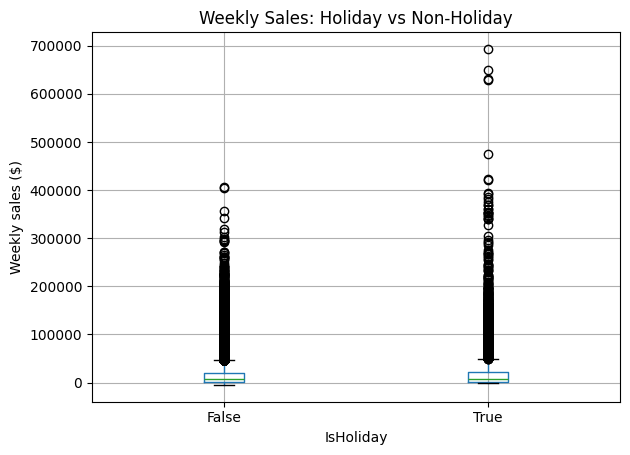

In [11]:
holiday_summary = df.groupby("IsHoliday")["Weekly_Sales"].agg(["count", "mean", "median", "sum"])
display(holiday_summary)

plt.figure(figsize=(7, 5))
df.boxplot(column="Weekly_Sales", by="IsHoliday")
plt.title("Weekly Sales: Holiday vs Non-Holiday")
plt.suptitle("")
plt.xlabel("IsHoliday")
plt.ylabel("Weekly sales ($)")
plt.tight_layout()
plt.show()

## 14. EDA: store type and store size

Store type and size may be associated with different sales volumes. This is descriptive analysis; it does not prove that store type or size causes higher sales.

,Total sales
Type,
A,4.331015e+09
B,2.000701e+09
C,4.055035e+08


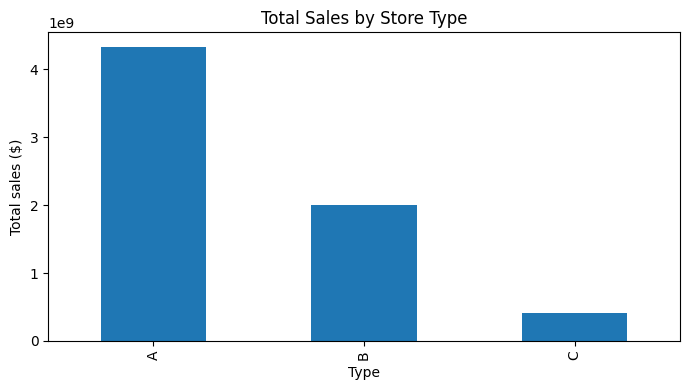

,Store,Size
12,13,219622
10,11,207499
27,28,206302
3,4,205863
26,27,204184
23,24,203819
18,19,203819
30,31,203750
19,20,203742
31,32,203007


In [12]:
if "Type" in df.columns:
    type_sales = df.groupby("Type")["Weekly_Sales"].sum().sort_values(ascending=False)
    display(type_sales.to_frame("Total sales"))
    type_sales.plot(kind="bar", figsize=(7, 4), title="Total Sales by Store Type")
    plt.ylabel("Total sales ($)")
    plt.tight_layout()
    plt.show()

if "Size" in df.columns:
    store_size = stores_raw[["Store", "Size"]].drop_duplicates()
    display(store_size.sort_values("Size", ascending=False).head(10))

## 15. EDA: highest-selling departments

This chart identifies departments with the largest total sales across the historical period. It helps show why demand patterns may differ between departments.

,Total sales
Dept,
92,4.839433e+08
95,4.493202e+08
38,3.931181e+08
72,3.057252e+08
90,2.910685e+08
40,2.889360e+08
2,2.806112e+08
91,2.167817e+08
13,1.973216e+08


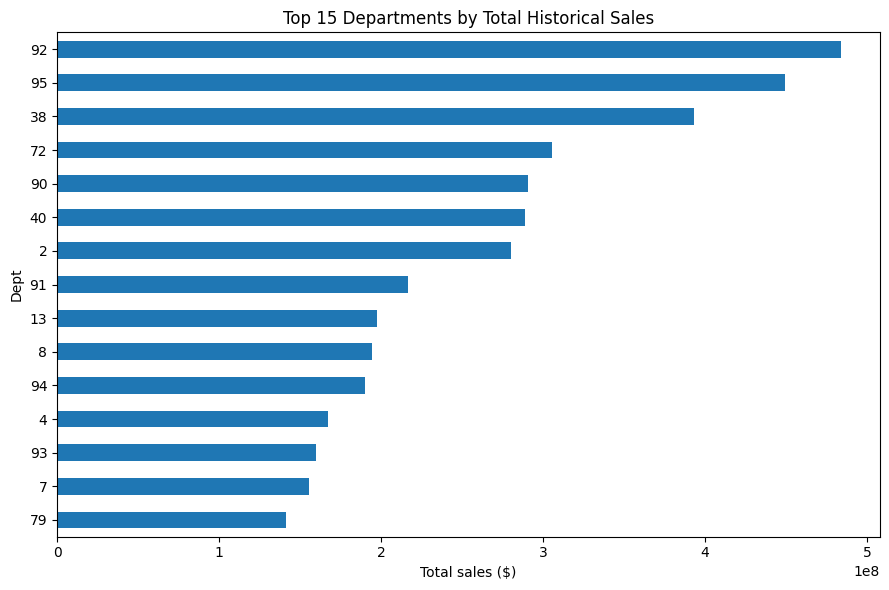

In [13]:
dept_sales = df.groupby("Dept")["Weekly_Sales"].sum().sort_values(ascending=False)
display(dept_sales.head(15).to_frame("Total sales"))

dept_sales.head(15).sort_values().plot(kind="barh", figsize=(9, 6))
plt.title("Top 15 Departments by Total Historical Sales")
plt.xlabel("Total sales ($)")
plt.tight_layout()
plt.show()

## 16. EDA: correlations between numerical variables

Correlation measures linear association between numeric variables. It is useful for exploration, but correlation alone does not establish causation and does not guarantee predictive usefulness.

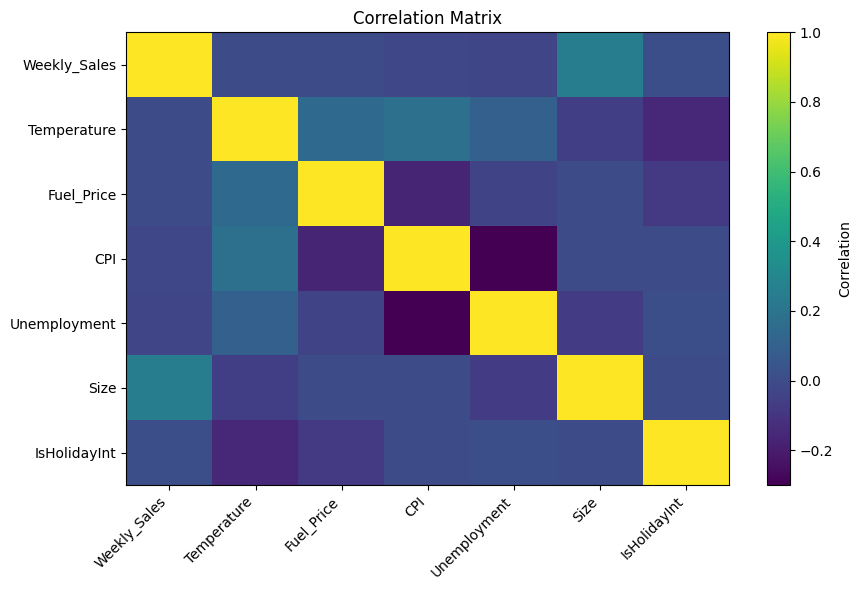

In [14]:
corr_cols = [
    c for c in ["Weekly_Sales", "Temperature", "Fuel_Price", "CPI",
                "Unemployment", "Size", "IsHolidayInt"]
    if c in df.columns
]
corr = df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(9, 6))
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

## 17. Choose the modelling level: department-week demand

The raw data contains many Store–Department rows per date. To make a manageable and consistent comparison across all five models, we aggregate sales across stores for each department and week.

The modelling table therefore has one row per **Department–Date**:
- `Weekly_Sales` is summed across stores.
- Economic and weather variables are averaged across stores for that department-week.
- Holiday status is retained as a weekly indicator.
- Store size is averaged across stores.

**Interpretation:** forecasts represent total demand for a department across Walmart stores. This is useful for department-level planning, but it is not a separate forecast for every store.

In [15]:
agg_spec = {
    "Weekly_Sales": "sum",
    "IsHolidayInt": "max",
    "Temperature": "mean",
    "Fuel_Price": "mean",
    "CPI": "mean",
    "Unemployment": "mean",
    "Size": "mean",
    "Year": "first",
    "Month": "first",
    "Week": "first"
}
for col in [f"MarkDown{i}" for i in range(1, 6)]:
    if col in df.columns:
        agg_spec[col] = "mean"

dept_week = (
    df.groupby(["Dept", "Date"], as_index=False)
      .agg(agg_spec)
      .sort_values(["Dept", "Date"])
      .reset_index(drop=True)
)

print("Department-week rows:", len(dept_week))
print("Departments:", dept_week["Dept"].nunique())
print("Weeks:", dept_week["Date"].nunique())
display(dept_week.head())

Department-week rows: 11090
Departments: 81
Weeks: 143


,Dept,Date,Weekly_Sales,IsHolidayInt,Temperature,Fuel_Price,CPI,Unemployment,Size,Year,Month,Week,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5
0,1,2010-02-05,881833.41,0,34.037333,2.717844,167.730885,8.619311,130287.6,2010,2,5,0.0,0.0,0.0,0.0,0.0
1,1,2010-02-12,1457182.40,1,34.151333,2.694022,167.825608,8.619311,130287.6,2010,2,6,0.0,0.0,0.0,0.0,0.0
2,1,2010-02-19,1118257.36,0,37.719778,2.672067,167.871686,8.619311,130287.6,2010,2,7,0.0,0.0,0.0,0.0,0.0
3,1,2010-02-26,681391.58,0,39.243556,2.683933,167.909657,8.619311,130287.6,2010,2,8,0.0,0.0,0.0,0.0,0.0
4,1,2010-03-05,762652.57,0,42.917333,2.731200,167.947628,8.619311,130287.6,2010,3,9,0.0,0.0,0.0,0.0,0.0


## 18. Chronological train/validation split

We split on unique dates, not row positions. This ensures that every department's rows for a date belong to the same side of the split.

The final 20% of dates are validation data. Validation data is held aside when fitting model parameters and imputers.

In [16]:
all_dates = np.array(sorted(dept_week["Date"].unique()))
split_idx = int(len(all_dates) * 0.80)
train_dates = all_dates[:split_idx]
valid_dates = all_dates[split_idx:]
split_date = pd.Timestamp(valid_dates[0])

train_data = dept_week[dept_week["Date"] < split_date].copy()
valid_data = dept_week[dept_week["Date"] >= split_date].copy()

print("Training weeks:", len(train_dates))
print("Validation weeks:", len(valid_dates))
print("Training ends:", pd.Timestamp(train_dates[-1]).date())
print("Validation starts:", pd.Timestamp(valid_dates[0]).date())
print("Validation ends:", pd.Timestamp(valid_dates[-1]).date())
print("Training rows:", len(train_data), "| Validation rows:", len(valid_data))

Training weeks: 114
Validation weeks: 29
Training ends: 2012-04-06
Validation starts: 2012-04-13
Validation ends: 2012-10-26
Training rows: 8831 | Validation rows: 2259


## 19. Feature engineering: historical sales lags

Lag features represent earlier sales for the same department:
- Lag 1: previous week.
- Lag 2: two weeks earlier.
- Lag 4: four weeks earlier.
- Lag 13: approximately one quarter earlier.
- Lag 52: corresponding week one year earlier.

Rolling averages summarize recent demand. All rolling values are shifted by one week so that a row never uses its own target value.

In [17]:
panel = dept_week.sort_values(["Dept", "Date"]).reset_index(drop=True).copy()
grouped_sales = panel.groupby("Dept")["Weekly_Sales"]

for lag in [1, 2, 4, 13, 52]:
    panel[f"Lag_{lag}"] = grouped_sales.shift(lag)

panel["RollingMean_4"] = panel.groupby("Dept")["Weekly_Sales"].transform(
    lambda s: s.shift(1).rolling(4, min_periods=1).mean()
)
panel["RollingMean_8"] = panel.groupby("Dept")["Weekly_Sales"].transform(
    lambda s: s.shift(1).rolling(8, min_periods=1).mean()
)

lag_features = [
    "Lag_1", "Lag_2", "Lag_4", "Lag_13", "Lag_52",
    "RollingMean_4", "RollingMean_8"
]
base_features = [
    "Dept", "Temperature", "Fuel_Price", "CPI", "Unemployment",
    "Size", "Year", "Month", "Week", "IsHolidayInt"
]
feature_cols = base_features + lag_features

panel_train = panel[panel["Date"] < split_date].copy()
panel_valid = panel[panel["Date"] >= split_date].copy()
print("Features:", feature_cols)
print("Training rows:", len(panel_train), "| Validation rows:", len(panel_valid))

Features: ['Dept', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Size', 'Year', 'Month', 'Week', 'IsHolidayInt', 'Lag_1', 'Lag_2', 'Lag_4', 'Lag_13', 'Lag_52', 'RollingMean_4', 'RollingMean_8']
Training rows: 8831 | Validation rows: 2259


## 20. Evaluation metrics: MAE, RMSE and WMAE

We report three metrics.

**MAE — Mean Absolute Error**
\[
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|
\]
It gives the average absolute prediction error in sales units.

**RMSE — Root Mean Squared Error**
\[
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}
\]
It penalizes large errors more heavily than MAE.

**WMAE — Weighted Mean Absolute Error**
\[
WMAE = \frac{\sum_i w_i|y_i-\hat y_i|}{\sum_i w_i}
\]
Holiday observations receive weight 5 and non-holiday observations receive weight 1.

For all three metrics, **lower is better**. WMAE is the primary comparison metric for this project.

In [18]:
def calculate_metrics(y_true, y_pred, holiday_flags):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    weights = np.where(np.asarray(holiday_flags, dtype=bool), 5.0, 1.0)
    errors = y_true - y_pred
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "WMAE": float(np.sum(weights * np.abs(errors)) / np.sum(weights))
    }

## 21. Model 1 — Seasonal Naive baseline

A baseline is a simple forecasting method used as a reference point. Seasonal Naive predicts a department's sales using the sales from the corresponding week 52 weeks earlier.

If that exact historical week is unavailable, the model uses that department's average training-period sales as a fallback. The fallback count is printed so its use is transparent.

In [19]:
sales_history = panel.set_index(["Dept", "Date"])["Weekly_Sales"]
dept_train_mean = panel_train.groupby("Dept")["Weekly_Sales"].mean()
global_train_mean = float(panel_train["Weekly_Sales"].mean())

naive_preds = []
fallback_count = 0
for row in panel_valid[["Dept", "Date"]].itertuples(index=False):
    previous_date = row.Date - pd.Timedelta(weeks=52)
    value = sales_history.get((row.Dept, previous_date), np.nan)
    if pd.isna(value):
        fallback_count += 1
        value = dept_train_mean.get(row.Dept, global_train_mean)
    naive_preds.append(float(value))

naive_preds = np.maximum(0, np.asarray(naive_preds))
print("Seasonal Naive validation predictions:", len(naive_preds))
print("Department-week rows using mean fallback:", fallback_count)

Seasonal Naive validation predictions: 2259
Department-week rows using mean fallback: 39


## 22. Model 2 — Random Forest Regressor

Random Forest trains many decision trees on different samples and combines their predictions. It can model non-linear relationships between calendar variables, external features and historical sales.

We fit the median imputer on training data only. The validation set is transformed using the same imputer. The model is evaluated on the same Department–Week validation rows as the other approaches.

In [20]:
imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(panel_train[feature_cols])
X_valid = imputer.transform(panel_valid[feature_cols])
y_train = panel_train["Weekly_Sales"].to_numpy(dtype=float)

rf_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=18,
    min_samples_leaf=2,
    random_state=SEED,
    n_jobs=-1
)
print("Training Random Forest...")
rf_model.fit(X_train, y_train)
rf_preds = np.maximum(0, rf_model.predict(X_valid))
print("Random Forest validation predictions:", len(rf_preds))

Training Random Forest...
Random Forest validation predictions: 2259


## 23. Model 3 — XGBoost Regressor

XGBoost is a gradient-boosting algorithm. It builds decision trees sequentially, with later trees learning patterns in the errors made by earlier trees.

We use the same engineered features and the same chronological validation set as Random Forest. This makes the comparison more consistent.

In [21]:
xgb_model = XGBRegressor(
    n_estimators=400,
    learning_rate=0.04,
    max_depth=7,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="reg:squarederror",
    eval_metric="mae",
    random_state=SEED,
    n_jobs=-1
)
print("Training XGBoost...")
xgb_model.fit(X_train, y_train, verbose=False)
xgb_preds = np.maximum(0, xgb_model.predict(X_valid))
print("XGBoost validation predictions:", len(xgb_preds))

Training XGBoost...
XGBoost validation predictions: 2259


## 24. Model 4 — LSTM: sequence preparation

LSTM is a recurrent neural network designed to learn dependencies in sequential data. Unlike a model that sees only one row at a time, this LSTM receives the previous **8 weekly observations** for the same department.

The input sequence contains historical sales and selected external/calendar variables. The target is the next week's department sales.

The scaler is fitted using training-period rows only. Validation sequences may use actual previous validation weeks as history, matching our rolling one-week-ahead evaluation protocol.

In [45]:
SEQ_LEN = 8
lstm_features = [
    "Weekly_Sales", "Temperature", "Fuel_Price", "CPI",
    "Unemployment", "IsHolidayInt", "Month", "Week"
]

lstm_frame = panel.copy()
train_lstm_frame = lstm_frame[lstm_frame["Date"] < split_date]
lstm_medians = train_lstm_frame[lstm_features].median(numeric_only=True)
lstm_frame[lstm_features] = lstm_frame[lstm_features].fillna(lstm_medians)

scaler = StandardScaler()
scaler.fit(lstm_frame.loc[lstm_frame["Date"] < split_date, lstm_features])
scaled_array = scaler.transform(lstm_frame[lstm_features]).astype(np.float32)

X_seq, y_seq, target_rows = [], [], []
for dept, group in lstm_frame.groupby("Dept", sort=False):
    row_ids = group.index.to_numpy()
    for pos in range(SEQ_LEN, len(row_ids)):
        target_row = int(row_ids[pos])
        X_seq.append(scaled_array[row_ids[pos-SEQ_LEN:pos]])
        y_seq.append(float(panel.loc[target_row, "Weekly_Sales"]))
        target_rows.append(target_row)

X_seq = np.asarray(X_seq, dtype=np.float32)
y_seq = np.asarray(y_seq, dtype=np.float32)
target_rows = np.asarray(target_rows, dtype=np.int64)
target_dates = panel.loc[target_rows, "Date"].to_numpy()

train_seq_mask = target_dates < split_date
valid_seq_mask = target_dates >= split_date

# Scale the target variable using training data only
target_scaler = StandardScaler()

target_scaler.fit(
    y_seq[train_seq_mask].reshape(-1, 1)
)

y_seq_scaled = target_scaler.transform(
    y_seq.reshape(-1, 1)
).ravel()

print("Target scaling completed.")
print("Training target mean:", target_scaler.mean_[0])
print("Training target scale:", target_scaler.scale_[0])


X_lstm_train = torch.tensor(X_seq[train_seq_mask], dtype=torch.float32)
y_lstm_train = torch.tensor(
    y_seq_scaled[train_seq_mask],
    dtype=torch.float32
).reshape(-1, 1)
X_lstm_valid = torch.tensor(X_seq[valid_seq_mask], dtype=torch.float32)
lstm_valid_rows = target_rows[valid_seq_mask]

print("LSTM training sequences:", len(X_lstm_train))
print("LSTM validation sequences:", len(X_lstm_valid))

Target scaling completed.
Training target mean: 612268.249531456
Training target scale: 763993.658937458
LSTM training sequences: 8184
LSTM validation sequences: 2258


## 25. Model 4 — LSTM: define, train and predict

The LSTM layer reads the 8-week sequence. Its final hidden representation passes through dense layers to produce a sales prediction.

We train for a small number of epochs to keep Colab runtime manageable. Training loss is printed after each epoch. More epochs or hyperparameter tuning may improve performance, but should be selected using validation discipline.

In [47]:
class DepartmentLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim=48):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, batch_first=True)
        self.regressor = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        output, _ = self.lstm(x)
        return self.regressor(output[:, -1, :])

lstm_model = DepartmentLSTM(input_dim=len(lstm_features)).to(DEVICE)
train_loader = DataLoader(
    TensorDataset(X_lstm_train, y_lstm_train),
    batch_size=512,
    shuffle=True
)
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.001)
loss_function = nn.MSELoss()

EPOCHS = 8
for epoch in range(EPOCHS):
    lstm_model.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        prediction = lstm_model(xb)
        loss = loss_function(prediction, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
    print(f"Epoch {epoch+1}/{EPOCHS} - training MSE: {total_loss/len(X_lstm_train):,.2f}")

lstm_model.eval()
lstm_preds_list = []
with torch.no_grad():
    validation_loader = DataLoader(X_lstm_valid, batch_size=1024, shuffle=False)
    for xb in validation_loader:
        lstm_preds_list.extend(lstm_model(xb.to(DEVICE)).cpu().numpy().ravel())

# Convert scaled predictions back to original sales values
lstm_preds_scaled = np.asarray(
    lstm_preds_list, dtype=float
).reshape(-1, 1)

lstm_preds = target_scaler.inverse_transform(
    lstm_preds_scaled
).ravel()

# Sales cannot be negative
lstm_preds = np.maximum(0, lstm_preds)

print("LSTM predictions:", len(lstm_preds))
print("Sample predictions:", lstm_preds[:5])


Epoch 1/8 - training MSE: 0.95
Epoch 2/8 - training MSE: 0.67
Epoch 3/8 - training MSE: 0.22
Epoch 4/8 - training MSE: 0.14
Epoch 5/8 - training MSE: 0.11
Epoch 6/8 - training MSE: 0.09
Epoch 7/8 - training MSE: 0.09
Epoch 8/8 - training MSE: 0.08
LSTM predictions: 2258
Sample predictions: [1421882.17534884 1454416.94807659 1281451.8211584  1128125.72787271
 1005920.8300466 ]


## 26. Model 5 — SARIMA: department-level time series

SARIMA extends ARIMA by modelling seasonal patterns. It uses:
- Autoregression (AR): dependence on previous observations.
- Integration (I): differencing to address non-stationarity.
- Moving Average (MA): dependence on past forecast errors.
- Seasonal terms: recurring patterns at a fixed seasonal interval.

We fit one SARIMA model per department using that department's weekly sales history. There are 81 departments in the original data. Each model forecasts the department's validation weeks.

In [35]:

sarima_predictions = []
sarima_failures = []
sarima_fitted_models = {}

for dept in sorted(panel["Dept"].unique()):

    dept_series = (
        panel.loc[
            (panel["Dept"] == dept) & (panel["Date"] < split_date)
        ]
        .sort_values("Date")["Weekly_Sales"]
        .to_numpy(dtype=float)
    )

    dept_valid = (
        panel.loc[
            (panel["Dept"] == dept) & (panel["Date"] >= split_date),
            ["Date", "Weekly_Sales"]
        ]
        .sort_values("Date")
    )

    if len(dept_series) < 60 or dept_valid.empty:
        sarima_failures.append((dept, "Insufficient history"))
        continue

    try:
        # Fit SARIMA using a numeric index to avoid date-index frequency errors.
        fitted = SARIMAX(
            dept_series,
            order=(1, 1, 1),
            seasonal_order=(1, 0, 0, 52),
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit(disp=False, maxiter=100)

    except Exception as exc:
        sarima_failures.append(
            (dept, f"SARIMA fitting failed: {str(exc)[:100]}")
        )
        continue

    sarima_fitted_models[int(dept)] = fitted
    current_fit = fitted

    # Rolling one-week-ahead forecasting
    for row in dept_valid.itertuples(index=False):

        prediction = float(
            np.asarray(current_fit.forecast(steps=1)).reshape(-1)[0]
        )

        sarima_predictions.append({
            "Dept": int(dept),
            "Date": pd.Timestamp(row.Date),
            "SARIMA_Prediction": max(0.0, prediction)
        })

        # Update model using the actual observed sales.
        actual_value = np.array(
            [float(row.Weekly_Sales)],
            dtype=float
        )

        current_fit = current_fit.append(
            actual_value,
            refit=False
        )

sarima_pred_df = pd.DataFrame(sarima_predictions)

print("SARIMA department-week forecasts:", len(sarima_pred_df))
print("SARIMA fitting failures:", len(sarima_failures))

display(
    pd.DataFrame(
        sarima_failures,
        columns=["Department", "Issue"]
    )
)


SARIMA department-week forecasts: 2240
SARIMA fitting failures: 3


,Department,Issue
0,39,Insufficient history
1,43,Insufficient history
2,77,Insufficient history


## 27. Align predictions from all models

All models must be evaluated on the same Department–Week rows. The LSTM needs eight weeks of history, so the first few dates in each department may not have LSTM predictions. We use the common intersection of rows available for all five models.

This avoids giving one model an easier or different evaluation sample.

In [48]:
validation_base = panel_valid[["Dept", "Date", "Weekly_Sales", "IsHolidayInt"]].copy()
validation_base = validation_base.rename(columns={"Weekly_Sales": "Actual"})

validation_base["Seasonal Naive"] = naive_preds
validation_base["Random Forest"] = rf_preds
validation_base["XGBoost"] = xgb_preds

lstm_map = pd.DataFrame({
    "Dept": panel.loc[lstm_valid_rows, "Dept"].to_numpy(),
    "Date": panel.loc[lstm_valid_rows, "Date"].to_numpy(),
    "LSTM": lstm_preds
})
validation_base = validation_base.merge(lstm_map, on=["Dept", "Date"], how="left")

validation_base = validation_base.merge(
    sarima_pred_df,
    on=["Dept", "Date"],
    how="left"
).rename(columns={"SARIMA_Prediction": "SARIMA"})

model_names = ["Seasonal Naive", "Random Forest", "XGBoost", "LSTM", "SARIMA"]
common_eval = validation_base.dropna(subset=model_names).copy()

print("Validation Department-Week rows before alignment:", len(validation_base))
print("Common rows used for all five models:", len(common_eval))
print("Validation weeks represented:", common_eval["Date"].nunique())
display(common_eval.head())

Validation Department-Week rows before alignment: 2259
Common rows used for all five models: 2240
Validation weeks represented: 29


,Dept,Date,Actual,IsHolidayInt,Seasonal Naive,Random Forest,XGBoost,LSTM,SARIMA
0,1,2012-04-13,1508832.27,0,1140811.14,1.411319e+06,1.631194e+06,1.421882e+06,2.037832e+06
1,1,2012-04-20,611916.32,0,2301887.84,2.404171e+06,1.500301e+06,1.454417e+06,2.013692e+06
2,1,2012-04-27,602250.63,0,1484108.24,9.594619e+05,9.837065e+05,1.281452e+06,6.289908e+05
3,1,2012-05-04,629152.80,0,649338.40,6.525216e+05,7.080912e+05,1.128126e+06,4.214168e+05
4,1,2012-05-11,666154.84,0,611503.25,6.400249e+05,7.032498e+05,1.005921e+06,6.840520e+05


## 28. Calculate model accuracy metrics

MAE, RMSE and WMAE are calculated over the common evaluation rows. Holiday rows receive weight 5 and non-holiday rows receive weight 1.

The model with the lowest WMAE is ranked first for the primary project comparison. Do not write a winner into the report until this cell has produced actual results.

In [49]:
def metric_values(actual, predicted, holiday):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    weights = np.where(np.asarray(holiday, dtype=bool), 5.0, 1.0)
    absolute_error = np.abs(actual - predicted)
    return {
        "MAE": float(np.mean(absolute_error)),
        "RMSE": float(np.sqrt(np.mean((actual - predicted) ** 2))),
        "WMAE": float(np.sum(weights * absolute_error) / np.sum(weights))
    }

metrics = {}
for model_name in model_names:
    metrics[model_name] = metric_values(
        common_eval["Actual"],
        common_eval[model_name],
        common_eval["IsHolidayInt"]
    )

metrics_df = pd.DataFrame(metrics).T.sort_values("WMAE")
display(metrics_df.round(2))
print("Best model by WMAE:", metrics_df.index[0])

,MAE,RMSE,WMAE
SARIMA,28633.07,80286.18,29130.27
Random Forest,30530.48,68866.77,30271.42
Seasonal Naive,33117.95,75744.70,32519.00
XGBoost,44241.06,79536.31,43432.78
LSTM,62185.64,99371.74,63027.73


Best model by WMAE: SARIMA


## 29. Visualize the model comparison

A WMAE bar chart makes it easier to compare the models. The lowest bar indicates the lowest holiday-weighted absolute error on this validation sample.

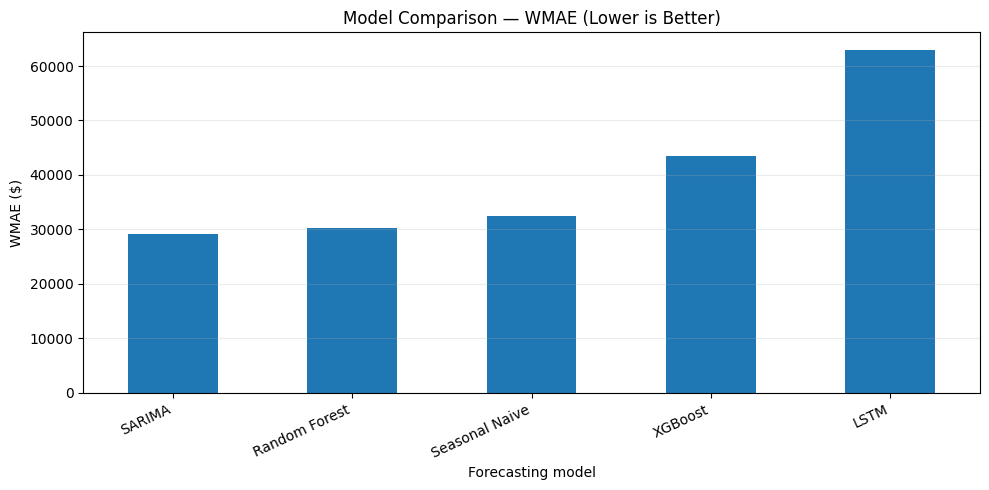

In [50]:
plt.figure(figsize=(10, 5))
metrics_df["WMAE"].sort_values().plot(kind="bar")
plt.title("Model Comparison — WMAE (Lower is Better)")
plt.xlabel("Forecasting model")
plt.ylabel("WMAE ($)")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 30. Actual versus predicted sales for a selected department

The next cell plots actual and predicted weekly sales for one department. Change `SELECTED_DEPT` to examine another department.

This plot helps show whether a model follows the direction and seasonal movement of actual demand.

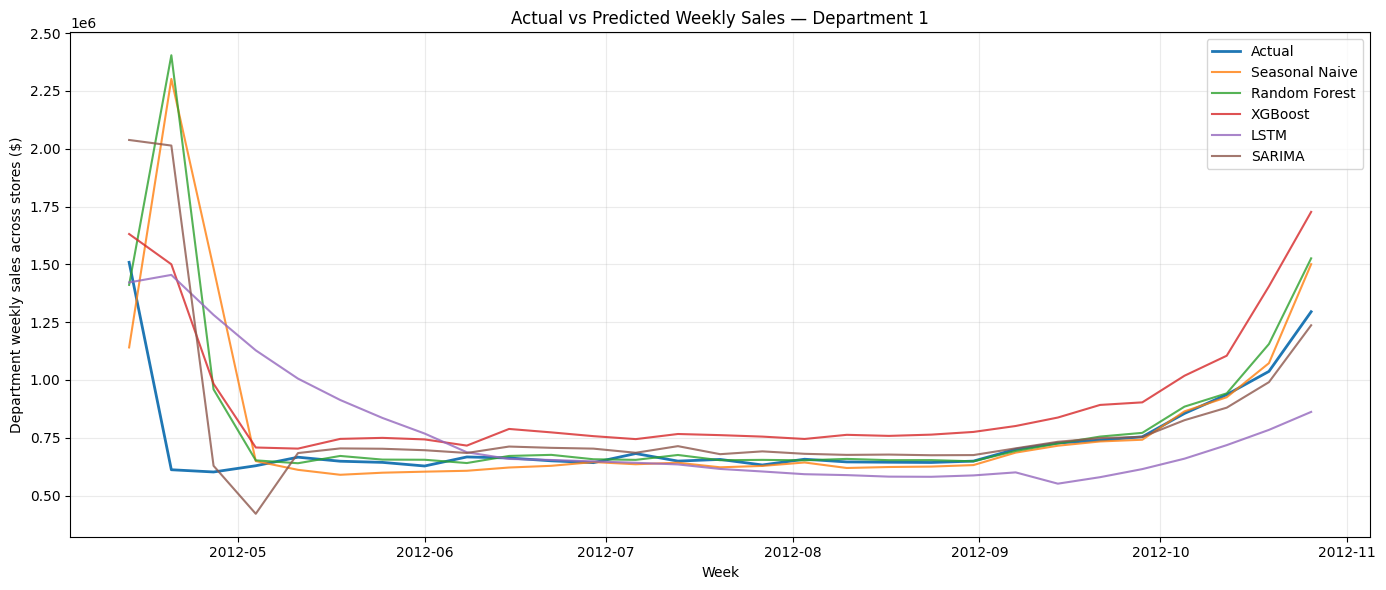

In [51]:
SELECTED_DEPT = int(sorted(common_eval["Dept"].unique())[0])
dept_plot = common_eval[common_eval["Dept"] == SELECTED_DEPT].sort_values("Date")

plt.figure(figsize=(14, 6))
plt.plot(dept_plot["Date"], dept_plot["Actual"], label="Actual", linewidth=2)
for model_name in model_names:
    plt.plot(dept_plot["Date"], dept_plot[model_name], label=model_name, alpha=0.8)
plt.title(f"Actual vs Predicted Weekly Sales — Department {SELECTED_DEPT}")
plt.xlabel("Week")
plt.ylabel("Department weekly sales across stores ($)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 31. Actual versus predicted sales: all departments combined

This chart sums department-level actuals and forecasts for each week. It provides an overall view, while the metrics above remain calculated at the Department–Week level.

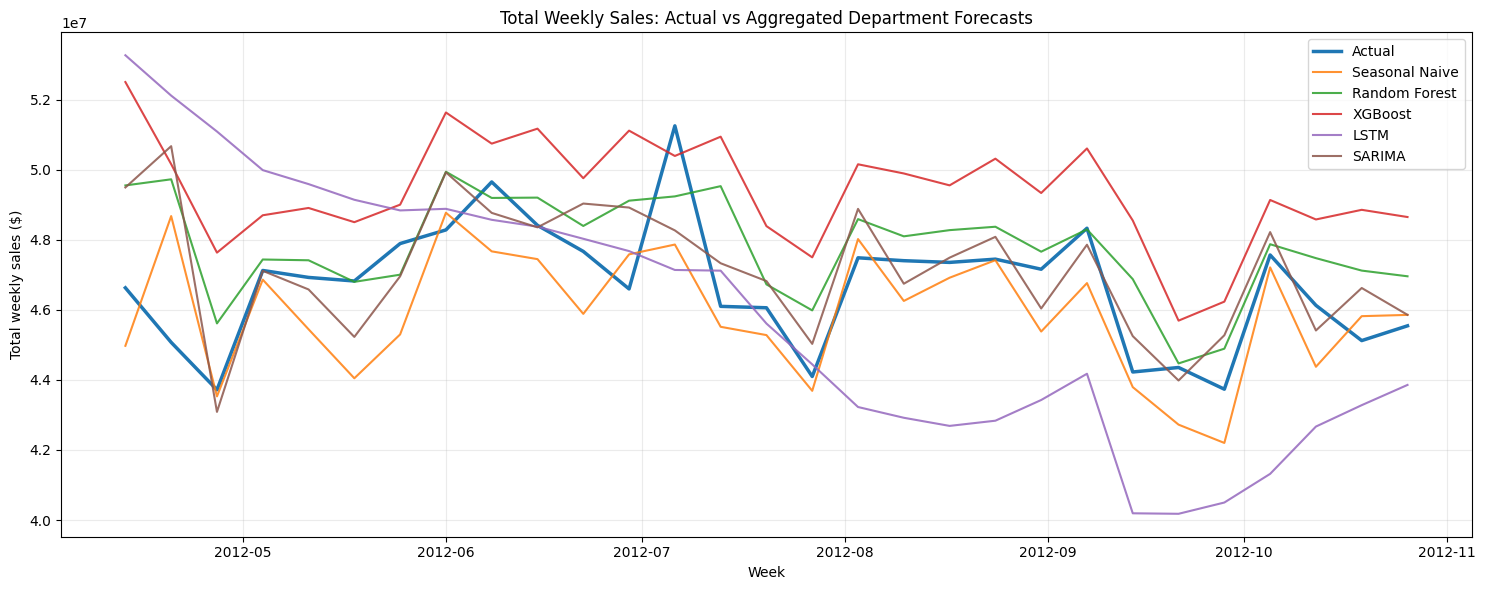

In [52]:
weekly_comparison = common_eval.groupby("Date")[["Actual"] + model_names].sum().sort_index()

plt.figure(figsize=(15, 6))
plt.plot(weekly_comparison.index, weekly_comparison["Actual"], label="Actual", linewidth=2.5)
for model_name in model_names:
    plt.plot(weekly_comparison.index, weekly_comparison[model_name], label=model_name, alpha=0.85)
plt.title("Total Weekly Sales: Actual vs Aggregated Department Forecasts")
plt.xlabel("Week")
plt.ylabel("Total weekly sales ($)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 32. Residual analysis for the best model

A residual is the difference between actual and predicted sales:

\[
Residual = Actual - Predicted
\]

Residuals close to zero indicate more accurate predictions. A consistent positive or negative residual pattern can indicate systematic underforecasting or overforecasting.

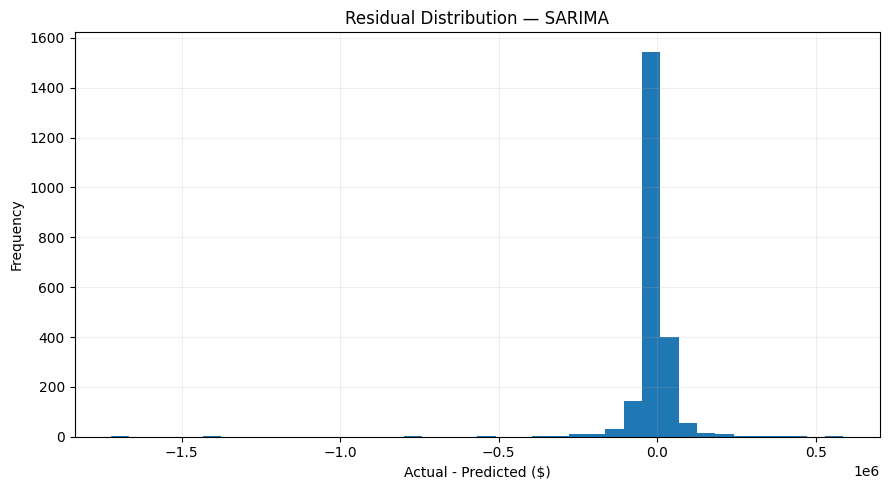

Mean residual: -5869.56
Median residual: -538.64


In [53]:
best_model_name = metrics_df.index[0]
common_eval["Best_Model_Residual"] = common_eval["Actual"] - common_eval[best_model_name]

plt.figure(figsize=(9, 5))
plt.hist(common_eval["Best_Model_Residual"], bins=40)
plt.title(f"Residual Distribution — {best_model_name}")
plt.xlabel("Actual - Predicted ($)")
plt.ylabel("Frequency")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Mean residual:", round(common_eval["Best_Model_Residual"].mean(), 2))
print("Median residual:", round(common_eval["Best_Model_Residual"].median(), 2))

## 33. Interpret the results for inventory planning

Use the direction of the forecast error carefully:
- **Positive residual (Actual > Predicted):** the model underforecast demand for that observation.
- **Negative residual (Actual < Predicted):** the model overforecast demand.
- **Residual near zero:** prediction was close to actual sales.

A forecast is an input to inventory planning, not an automatic order quantity. Real inventory decisions also require current stock, lead times, supplier constraints, safety stock, costs and service-level targets. This notebook does not calculate an optimized purchase order.

In [42]:
interpretation = common_eval.assign(
    Residual=common_eval["Actual"] - common_eval[best_model_name]
).groupby("Dept").agg(
    Mean_Actual=("Actual", "mean"),
    Mean_Predicted=(best_model_name, "mean"),
    Mean_Residual=("Residual", "mean")
).sort_values("Mean_Residual")

display(interpretation.head(10))
display(interpretation.tail(10))

,Mean_Actual,Mean_Predicted,Mean_Residual
Dept,,,
99,1.332487e+03,1.368030e+05,-135470.544506
1,7.402947e+05,8.180437e+05,-77749.033454
18,9.932303e+04,1.298773e+05,-30554.306741
7,9.431653e+05,9.628578e+05,-19692.578816
16,8.091439e+05,8.258880e+05,-16744.086501
38,2.736026e+06,2.751525e+06,-15499.767201
95,3.281795e+06,3.293960e+06,-12165.552438
5,7.093836e+05,7.210016e+05,-11617.940539
92,3.479939e+06,3.491122e+06,-11182.519870


,Mean_Actual,Mean_Predicted,Mean_Residual
Dept,,,
3,6.135781e+05,6.135290e+05,49.081480
28,2.032515e+04,2.023362e+04,91.522176
27,5.380584e+04,5.354273e+04,263.108339
49,2.541020e+05,2.538150e+05,287.030165
44,1.739679e+05,1.736538e+05,314.038178
31,9.756633e+04,9.677808e+04,788.257216
17,4.181140e+05,4.169907e+05,1123.240619
48,2.439864e+04,2.283479e+04,1563.850180
58,1.193024e+05,1.141573e+05,5145.108664


In [54]:

# CELL 54: FINAL MODEL COMPARISON

import pandas as pd
import numpy as np
from IPython.display import display

# Use the metrics calculated in Cell 28
final_comparison = metrics_df.copy().sort_values("WMAE")

print("=" * 75)
print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 75)

display(final_comparison.round(2))

# Identify the best model for each evaluation metric
best_mae_model = final_comparison["MAE"].idxmin()
best_rmse_model = final_comparison["RMSE"].idxmin()
best_wmae_model = final_comparison["WMAE"].idxmin()

print("\nBEST MODEL BY EACH METRIC")
print("-" * 45)
print(f"Lowest MAE  : {best_mae_model} ({final_comparison.loc[best_mae_model, 'MAE']:,.2f})")
print(f"Lowest RMSE : {best_rmse_model} ({final_comparison.loc[best_rmse_model, 'RMSE']:,.2f})")
print(f"Lowest WMAE : {best_wmae_model} ({final_comparison.loc[best_wmae_model, 'WMAE']:,.2f})")

print("\nEVALUATION DATASET")
print("-" * 45)
print(f"Common department-week observations: {len(common_eval):,}")
print(f"Validation weeks: {common_eval['Date'].nunique()}")
print(f"Departments represented: {common_eval['Dept'].nunique()}")
print(f"Validation period: {common_eval['Date'].min().date()} to {common_eval['Date'].max().date()}")

print("\nPrimary comparison metric: WMAE")
print("Holiday observations receive weight 5; regular observations receive weight 1.")


FINAL MODEL PERFORMANCE COMPARISON


,MAE,RMSE,WMAE
SARIMA,28633.07,80286.18,29130.27
Random Forest,30530.48,68866.77,30271.42
Seasonal Naive,33117.95,75744.70,32519.00
XGBoost,44241.06,79536.31,43432.78
LSTM,62185.64,99371.74,63027.73



BEST MODEL BY EACH METRIC
---------------------------------------------
Lowest MAE  : SARIMA (28,633.07)
Lowest RMSE : Random Forest (68,866.77)
Lowest WMAE : SARIMA (29,130.27)

EVALUATION DATASET
---------------------------------------------
Common department-week observations: 2,240
Validation weeks: 29
Departments represented: 78
Validation period: 2012-04-13 to 2012-10-26

Primary comparison metric: WMAE
Holiday observations receive weight 5; regular observations receive weight 1.


In [55]:

# CELL 55: FINAL RESULTS INTERPRETATION

ranking = final_comparison.sort_values("WMAE")
best_model = ranking.index[0]
second_model = ranking.index[1]

best_wmae = ranking.loc[best_model, "WMAE"]
second_wmae = ranking.loc[second_model, "WMAE"]

wmae_difference = second_wmae - best_wmae
wmae_improvement = (wmae_difference / second_wmae) * 100 if second_wmae else 0

print("=" * 75)
print("EXPERIMENTAL RESULTS AND INTERPRETATION")
print("=" * 75)

print(f"""
1. Five forecasting approaches were evaluated:
   Seasonal Naive, Random Forest, XGBoost, LSTM and SARIMA.

2. {best_model} achieved the lowest WMAE of {best_wmae:,.2f}.
   It is therefore the best model under the project's primary
   holiday-weighted evaluation criterion.

3. {best_model} was followed by {second_model},
   with a WMAE of {second_wmae:,.2f}.

4. The WMAE difference between these two models was
   {wmae_difference:,.2f} ({wmae_improvement:.2f}% relative to the
   second-ranked model).

5. The lowest MAE was achieved by {best_mae_model},
   while the lowest RMSE was achieved by {best_rmse_model}.

6. The results show that model performance depends on the
   evaluation metric. A model with the lowest WMAE does not
   necessarily have the lowest MAE or RMSE.

7. The comparison was performed on the common observations
   available for all five models, so the evaluation sample
   was consistent across models.
""")

print("WMAE ranking:")
display(ranking[["MAE", "RMSE", "WMAE"]].round(2))


EXPERIMENTAL RESULTS AND INTERPRETATION

1. Five forecasting approaches were evaluated:
   Seasonal Naive, Random Forest, XGBoost, LSTM and SARIMA.

2. SARIMA achieved the lowest WMAE of 29,130.27.
   It is therefore the best model under the project's primary
   holiday-weighted evaluation criterion.

3. SARIMA was followed by Random Forest,
   with a WMAE of 30,271.42.

4. The WMAE difference between these two models was
   1,141.16 (3.77% relative to the
   second-ranked model).

5. The lowest MAE was achieved by SARIMA,
   while the lowest RMSE was achieved by Random Forest.

6. The results show that model performance depends on the
   evaluation metric. A model with the lowest WMAE does not
   necessarily have the lowest MAE or RMSE.

7. The comparison was performed on the common observations
   available for all five models, so the evaluation sample
   was consistent across models.

WMAE ranking:


,MAE,RMSE,WMAE
SARIMA,28633.07,80286.18,29130.27
Random Forest,30530.48,68866.77,30271.42
Seasonal Naive,33117.95,75744.70,32519.00
XGBoost,44241.06,79536.31,43432.78
LSTM,62185.64,99371.74,63027.73


In [56]:

# CELL 56: PROJECT CONCLUSION AND FUTURE ENHANCEMENTS

print("=" * 75)
print("PROJECT CONCLUSION")
print("=" * 75)

print(f"""
PROJECT: WALMART SALES FORECASTING AND DEMAND PREDICTION

CONCLUSION

This project developed and evaluated a weekly sales forecasting
approach using the original Walmart Recruiting Store Sales
Forecasting dataset.

The dataset contains historical sales information from multiple
Walmart stores and departments, together with store, calendar,
holiday and economic features.

Five forecasting models were implemented and compared:
1. Seasonal Naive
2. Random Forest
3. XGBoost
4. Long Short-Term Memory (LSTM)
5. Seasonal Autoregressive Integrated Moving Average (SARIMA)

The models were evaluated using:
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Weighted Mean Absolute Error (WMAE)

FINAL FINDING

{best_model} achieved the lowest WMAE of {best_wmae:,.2f}
on the common validation sample. Therefore, it is the leading
model according to the project's primary holiday-weighted metric.

The results also demonstrate that different models perform
differently across MAE, RMSE and WMAE. Model selection should
therefore consider the business objective and the cost of
forecasting errors, particularly during holiday periods.

BUSINESS RELEVANCE

More reliable weekly demand forecasts can support:
- Better inventory and replenishment planning.
- Reduced risk of excess inventory.
- Reduced risk of stockouts.
- Improved preparation for seasonal and holiday demand.

LIMITATIONS

- The dataset covers historical weeks from February 2010
  to October 2012.
- The validation period contains 29 weeks.
- The common comparison sample contains 2,240 observations.
- Some department-week predictions were unavailable for every
  model and were excluded from the common comparison.
- Historical validation performance does not guarantee the
  same performance on future unseen data.

FUTURE ENHANCEMENTS

- Evaluate additional forecasting algorithms.
- Tune model hyperparameters systematically.
- Explore longer historical datasets.
- Improve holiday and seasonal feature engineering.
- Test forecasts on newer unseen sales data.
- Retrain models as new weekly sales information becomes available.

OVERALL CONCLUSION

The project demonstrates how statistical, machine-learning and
deep-learning methods can be compared for retail demand forecasting.
The experimental results provide a data-driven basis for selecting
a forecasting model to support Walmart inventory planning.
""")


PROJECT CONCLUSION

PROJECT: WALMART SALES FORECASTING AND DEMAND PREDICTION

CONCLUSION

This project developed and evaluated a weekly sales forecasting
approach using the original Walmart Recruiting Store Sales
Forecasting dataset.

The dataset contains historical sales information from multiple
Walmart stores and departments, together with store, calendar,
holiday and economic features.

Five forecasting models were implemented and compared:
1. Seasonal Naive
2. Random Forest
3. XGBoost
4. Long Short-Term Memory (LSTM)
5. Seasonal Autoregressive Integrated Moving Average (SARIMA)

The models were evaluated using:
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Weighted Mean Absolute Error (WMAE)

FINAL FINDING

SARIMA achieved the lowest WMAE of 29,130.27
on the common validation sample. Therefore, it is the leading
model according to the project's primary holiday-weighted metric.

The results also demonstrate that different models perform
differently across MAE, RMSE

## 34. Save the model artifacts and evaluation results

This cell saves:
- Random Forest and XGBoost models.
- Feature imputer.
- LSTM model weights and scaler.
- SARIMA fitted models by department where available.
- Accuracy metrics.
- Validation predictions.
- Model comparison table.
- Metadata describing the experiment.

The output ZIP can be downloaded and retained with the project.

In [43]:
from google.colab import files

ARTIFACT_DIR = Path("/content/walmart_forecasting_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(imputer, ARTIFACT_DIR / "feature_imputer.joblib")
joblib.dump(rf_model, ARTIFACT_DIR / "random_forest.joblib")
joblib.dump(xgb_model, ARTIFACT_DIR / "xgboost.joblib")
joblib.dump(scaler, ARTIFACT_DIR / "lstm_scaler.joblib")
joblib.dump(lstm_medians.to_dict(), ARTIFACT_DIR / "lstm_medians.joblib")
joblib.dump(sarima_fitted_models, ARTIFACT_DIR / "sarima_department_models.joblib")

torch.save({
    "model_state_dict": lstm_model.state_dict(),
    "input_dim": len(lstm_features),
    "hidden_dim": 48,
    "sequence_length": SEQ_LEN,
    "feature_columns": lstm_features
}, ARTIFACT_DIR / "lstm_model.pt")

with open(ARTIFACT_DIR / "metrics.json", "w") as f:
    json.dump(
        {name: {key: round(float(value), 4) for key, value in result.items()}
         for name, result in metrics.items()},
        f, indent=4
    )

common_eval.to_csv(ARTIFACT_DIR / "validation_predictions.csv", index=False)
metrics_df.to_csv(ARTIFACT_DIR / "model_comparison.csv")

metadata = {
    "project": "Walmart Sales Forecasting and Demand Prediction",
    "target_level": "Department-week aggregated across stores",
    "training_weeks": int(len(train_dates)),
    "validation_weeks": int(len(valid_dates)),
    "training_end": str(pd.Timestamp(train_dates[-1]).date()),
    "validation_start": str(pd.Timestamp(valid_dates[0]).date()),
    "validation_end": str(pd.Timestamp(valid_dates[-1]).date()),
    "validation_protocol": "rolling one-week-ahead",
    "holiday_weights": {"holiday": 5, "non_holiday": 1},
    "primary_metric": "WMAE",
    "best_model_by_wmae": str(best_model_name),
    "models": model_names
}
with open(ARTIFACT_DIR / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

zip_path = "/content/walmart_forecasting_artifacts.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in ARTIFACT_DIR.iterdir():
        archive.write(path, arcname=path.name)

print("Saved files:", sorted(p.name for p in ARTIFACT_DIR.iterdir()))
files.download(zip_path)

Saved files: ['feature_imputer.joblib', 'lstm_medians.joblib', 'lstm_model.pt', 'lstm_scaler.joblib', 'metadata.json', 'metrics.json', 'model_comparison.csv', 'random_forest.joblib', 'sarima_department_models.joblib', 'validation_predictions.csv', 'xgboost.joblib']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 35. Final project report summary

After the notebook runs successfully, use the generated values to complete this summary:

- Dataset: Walmart Recruiting Store Sales Forecasting.
- Target: department-level weekly sales aggregated across stores.
- Training period: printed in the chronological split cell.
- Validation period: printed in the chronological split cell.
- Models compared: Seasonal Naive, Random Forest, XGBoost, LSTM and SARIMA.
- Metrics: MAE, RMSE and holiday-weighted WMAE.
- Best model: the model with the lowest validation WMAE, printed in the results cell.
- Inventory interpretation: inspect overforecasting and underforecasting patterns using residuals.

**Never insert invented accuracy values.** Copy the metrics from the executed `metrics_df` table.

## 36. Limitations and future improvements

1. **Historical period:** the supplied training data ends in October 2012; results may not represent current retail conditions.
2. **Forecasting level:** forecasts are department totals across stores, not individual Store–Department predictions.
3. **Validation protocol:** this is rolling one-week-ahead evaluation. A multi-week forecast issued once requires recursive forecasting or a multi-horizon model.
4. **SARIMA runtime:** one statistical model is fitted per department. Some departments may use the documented non-seasonal fallback if seasonal fitting fails.
5. **Inventory decisions:** forecasts alone do not optimize order quantities. Stock on hand, supplier lead time, safety stock and service-level targets are also needed.
6. **Further work:** evaluate store-department-level models, tune hyperparameters, test additional seasonal methods, and run rolling-origin backtesting.

## 37. Conclusion

This project demonstrates an end-to-end forecasting workflow using historical Walmart weekly sales. It combines data preprocessing, exploratory analysis, lag-based feature engineering, statistical forecasting, machine learning and deep learning.

The five approaches are evaluated on a common chronological validation set using MAE, RMSE and holiday-weighted WMAE. The best-performing model is selected from the actual validation results, and its forecast errors are interpreted in the context of overstocking and stockout risk.

**Final takeaway:** reliable demand forecasting can support better inventory planning, but operational ordering decisions should also account for inventory position, lead times and business constraints.

## 38. References and documentation

- Walmart Recruiting Store Sales Forecasting dataset (Kaggle).
- Pandas documentation: https://pandas.pydata.org/docs/
- Scikit-learn documentation: https://scikit-learn.org/stable/
- XGBoost documentation: https://xgboost.readthedocs.io/
- PyTorch documentation: https://pytorch.org/docs/
- Statsmodels documentation: https://www.statsmodels.org/
- Matplotlib documentation: https://matplotlib.org/stable/

Add the specific research papers used by your team to the final project reference list.